# Lab 2 in depth: from the moist-air sheet to the comfort sheet

This notebook follows the two sheets in the order you received them, using the lecture slides (*Occupants' Comfort & Health*) as the explanation.

| | Sheet | What it asks | Where it lives in this notebook |
|---|---|---|---|
| **1** | *Psychrometrics Study Sheet Challenge* | Describe a summer and a winter day in Romania: $p_{sat}$, $p_v$, $x$, $t_{dp}$, $h$, then the same for a whole day (24 h of Meteonorm data) | **Part A** |
| **2** | *AI for Energy Lab 2* | Code that returns PMV, PPD, $t_o$, number of iterations, then find an indoor state with $-0.5<PMV<0.5$ | **Part B** |

**How they connect.** Sheet 1 is about the *air* (how much water it holds, how much energy it carries). Sheet 2 is about the *person* in that air. The water-vapour pressure $p_v$ you compute in sheet 1 is exactly the $p_v$ that feeds two of the six body heat-loss paths in sheet 2.

Formulas come from the lecture slides. Where I add an assumption (for example an emissivity) it is flagged.

In [1]:
import sys; sys.path.insert(0, "../../shared")  # folder holding calculate_pmv_ppd.py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from calculate_pmv_ppd import calculate_pmv_ppd

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, MUTED, GRID, BAND = "#0b0b0b", "#52514e", "#e4e3df", "#ecebe7"
plt.rcParams.update({"axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "figure.dpi": 110, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold"})
SUMMER, WINTER = ORANGE, BLUE      # fixed colours: orange = summer, blue = winter, in every chart

# Part A: Sheet 1, the moist-air (psychrometrics) challenge

## A0. Vocabulary

| Term | Meaning | Symbol / unit |
|---|---|---|
| **Moist air** | The air around us: **dry air + water vapour**. We treat it as only these two ingredients. | - |
| **Psychrometrics** | The study of the properties of moist air. | - |
| **Ideal gas** | A gas simple enough to follow $pV = mRT$. Dry air, vapour and their mixture are all treated this way. | - |
| **Dalton's law** | Total pressure = pressure of dry air + pressure of vapour: $p = p_a + p_v$. Each gas pushes as if it were alone. | Pa |
| **Partial vapour pressure** $p_v$ | The share of the total pressure that is due to water vapour. It measures **how much** water is in the air. | Pa |
| **Saturation pressure** $p_{sat}(t)$ | The **most** vapour pressure air can have at temperature $t$. Above it, water condenses. Rises quickly with $t$. | Pa |
| **Relative humidity** $\varphi$ | How full the air is: $\varphi = p_v / p_{sat}(t)$. | % (or fraction) |
| **Humidity ratio** $x$ | Mass of vapour per mass of **dry** air: $x = m_v/m_a = 0.622\,\dfrac{p_v}{p-p_v}$. | kg/kg (often g/kg) |
| **Dew point** $t_{dp}$ | The temperature to which you must cool the air, with no water added or removed, for it to become saturated (fog / dew). Defined by $p_{sat}(t_{dp}) = p_v$. | °C |
| **Dry-bulb temperature** | The ordinary thermometer reading $t$. | °C |
| **Wet-bulb temperature** | Reading of a thermometer wrapped in a wet cloth: evaporation cools it, more so in dry air. (Not needed for this sheet.) | °C |
| **Enthalpy** $h$ | Total **heat energy carried by 1 kg of dry air**: warmth (sensible) + energy hidden in the vapour (latent). $h \approx t + x(2500+1.84\,t)$. | kJ/kg |

The constant 0.622 is the ratio of molar masses, water (18) / air (29). The 2500 kJ/kg is the energy needed to evaporate 1 kg of water, and 1.84 kJ/(kg·K) is the vapour's specific heat.

## A1. Lecture challenge: mass and density of the air in a room

Room 6 m × 4 m × 3 m, $p$ = 1 bar = 10⁵ Pa, 25 °C. Ideal gas law $pV = mRT$ with $R$ = 287 J/(kg·K) for air, $T$ in kelvin (25 + 273.15).

$$m = \frac{pV}{RT}\;[\mathrm{kg}],\qquad \rho = \frac{m}{V} = \frac{p}{RT}\;[\mathrm{kg/m^3}]$$

V = 72 m3   m = 84.14 kg   rho = 1.17 kg/m3


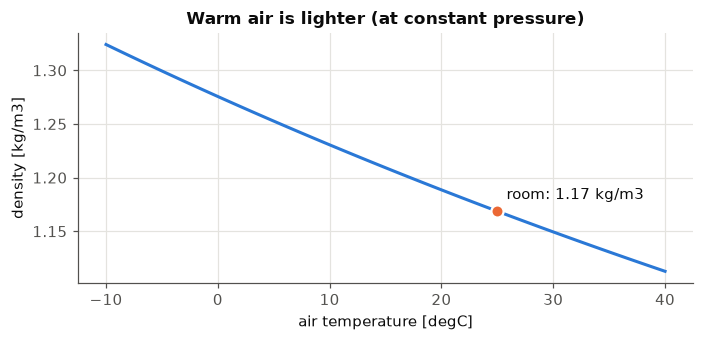

In [2]:
p, R = 1e5, 287                              # Pa, J/(kg.K)
V = 6 * 4 * 3                                # m3
T = 25 + 273.15                              # K
m = p * V / (R * T)                          # kg
rho = m / V                                  # kg/m3
print(f"V = {V} m3   m = {m:.2f} kg   rho = {rho:.2f} kg/m3")   # lecture: 84.14 kg and 84.14/72 = 1.17 kg/m3 (the slide writes 1.16)

t = np.linspace(-10, 40, 100)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(t, p / (R * (t + 273.15)), color=BLUE, lw=2)
ax.plot(25, rho, "o", color=ORANGE, ms=8, mec="white", mew=1.5); ax.annotate(f"room: {rho:.2f} kg/m3", (25, rho), xytext=(6, 8), textcoords="offset points")
ax.set_xlabel("air temperature [degC]"); ax.set_ylabel("density [kg/m3]"); ax.set_title("Warm air is lighter (at constant pressure)")
plt.tight_layout(); plt.show()

**Reading it.** Same pressure, hotter air means the molecules are more spread out, so each m³ weighs less. This is why warm air rises. The room holds about **84 kg of air**, far more than most people guess.

## A2. The data table: how much water can air hold?

The sheet gives measured saturation pressures of water. Between table points we interpolate linearly (a straight line between neighbours). Error is under about 1 %, fine for this lab.

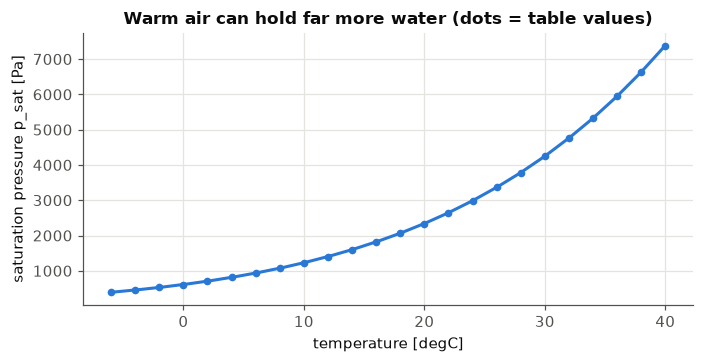

In [3]:
T_TAB = np.arange(-6, 41, 2)
P_TAB = np.array([390.9, 454.9, 527.9, 611.2, 706, 813.5, 935.3, 1073, 1228, 1403, 1599, 1819,
                  2065, 2339, 2645, 2986, 3364, 3783, 4247, 4760, 5325, 5948, 6633, 7385])

def p_sat(t):          # saturation pressure [Pa] by interpolating the sheet's table
    return np.interp(t, T_TAB, P_TAB)

def t_sat(pv):         # inverse: temperature [degC] at which p_sat = pv (this is the dew point)
    return np.interp(pv, P_TAB, T_TAB)

P_ATM = 1e5            # 1 bar [Pa]
def humidity_ratio(pv, p=P_ATM):  return 0.622 * pv / (p - pv)                 # kg water / kg dry air
def enthalpy(t, x):               return t + x * (2500 + 1.84 * t)               # kJ/kg dry air

tt = np.linspace(-6, 40, 200)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.plot(tt, p_sat(tt), color=BLUE, lw=2)
ax.plot(T_TAB, P_TAB, "o", color=BLUE, ms=4)
ax.set_xlabel("temperature [degC]"); ax.set_ylabel("saturation pressure p_sat [Pa]")
ax.set_title("Warm air can hold far more water (dots = table values)")
plt.tight_layout(); plt.show()

**Reading it.** The curve bends upward: from 0 °C to 30 °C the capacity grows about **7 times** (611 → 4247 Pa). The shape is the reason a humid summer day and a humid winter day are so different.

## A3. Solving the sheet: summer day vs winter day

Both days: $p$ = 1 bar. Summer: $t$ = 30 °C, $\varphi$ = 60 %. Winter: $t$ = 0 °C, $\varphi$ = 85 %.

Steps for each day:

1. $p_{sat}(t)$ from the table.
2. $p_v = \varphi\cdot p_{sat}(t)$: the real water pressure.
3. $x = 0.622\,p_v/(p-p_v)$: grams of water per kg of dry air.
4. $t_{dp} = t_{sat}(p_v)$: look the value of $p_v$ up in the table **backwards** to get a temperature.
5. $h = t + x(2500 + 1.84\,t)$: energy per kg of dry air.

In [4]:
cases = {"Summer day": (30, 0.60), "Winter day": (0, 0.85)}
rows = {}
for name, (t, phi) in cases.items():
    ps = p_sat(t); pv = phi * ps; x = humidity_ratio(pv); tdp = t_sat(pv); h = enthalpy(t, x)
    rows[name] = {"t [degC]": t, "phi [%]": phi * 100, "p_sat(t) [Pa]": round(float(ps), 1), "p_v = phi*p_sat [Pa]": round(float(pv), 1),
                  "x [g/kg]": round(1000 * x, 2), "t_dp [degC]": round(float(tdp), 2), "h [kJ/kg]": round(h, 2)}
sheet1 = pd.DataFrame(rows)
sheet1

,Summer day,Winter day
t [degC],30.00,0.00
phi [%],60.00,85.00
p_sat(t) [Pa],4247.00,611.20
p_v = phi*p_sat [Pa],2548.20,519.50
x [g/kg],16.26,3.25
t_dp [degC],21.37,-2.23
h [kJ/kg],71.56,8.12


**Reading the table.**
- **Summer:** the air carries 16.3 g of water per kg of dry air. That is more than the Romanian yearly average (10 g/kg) and above the ASHRAE 55 limit (12 g/kg). Its dew point is 21.4 °C: any surface colder than that (a cold glass, an air-conditioner coil) will drip.
- **Winter:** only 3.2 g/kg. Dew point −2.2 °C: below that, frost or fog forms. Humidity of 85 % *sounds* wet, but cold air holds so little that the absolute amount of water is five times smaller than in summer.
- **Lesson:** relative humidity alone hides the real amount of water. $x$ (and $p_v$) tell the truth. Warm air at 60 % holds much more than cold air at 85 %.

**Worked by hand (so you can check every number).**

*Room (A1):* $V = 6\cdot4\cdot3 = 72$ m³, $T = 25+273.15 = 298.15$ K.
$m = \dfrac{10^5\cdot 72}{287\cdot 298.15} = \dfrac{7.2\cdot10^6}{85\,569} = 84.14$ kg, so $\rho = 84.14/72 = 1.169 \approx 1.17$ kg/m³.

*Summer, 30 °C, 60 %:*
1. $p_{sat}(30\,°C) = 4247$ Pa (table).
2. $p_v = 0.60\cdot 4247 = 2548.2$ Pa.
3. $x = 0.622\cdot\dfrac{2548.2}{100000-2548.2} = 0.622\cdot 0.026148 = 0.016264$ kg/kg $= 16.26$ g/kg.
4. $t_{dp}$: find the temperature whose $p_{sat}$ equals 2548.2 Pa in the table (interpolating between the two neighbouring rows) $\Rightarrow$ **21.37 °C**.
5. $h = 30 + 0.016264\,(2500+1.84\cdot30) = 30 + 0.016264\cdot 2555.2 = 30 + 41.56 = 71.56$ kJ/kg (30 sensible + 41.56 latent).

*Winter, 0 °C, 85 %:*
1. $p_{sat}(0\,°C) = 611.2$ Pa.
2. $p_v = 0.85\cdot 611.2 = 519.5$ Pa.
3. $x = 0.622\cdot\dfrac{519.5}{100000-519.5} = 0.622\cdot 0.005222 = 0.003248$ kg/kg $= 3.25$ g/kg.
4. $t_{dp}$ from the table at $p_{sat} = 519.5$ Pa $\Rightarrow$ **−2.23 °C**.
5. $h = 0 + 0.003248\,(2500+0) = 8.12$ kJ/kg (all latent, since $t=0$).

The code cell above does exactly these five steps; the numbers it prints should match these lines.

## A4. Dew point on the saturation curve

Start at the air's state (its $p_v$). Cool it **without adding or removing water**: $p_v$ stays the same (horizontal line) while the curve $p_{sat}(t)$ comes down to meet it. The meeting point is the dew point.

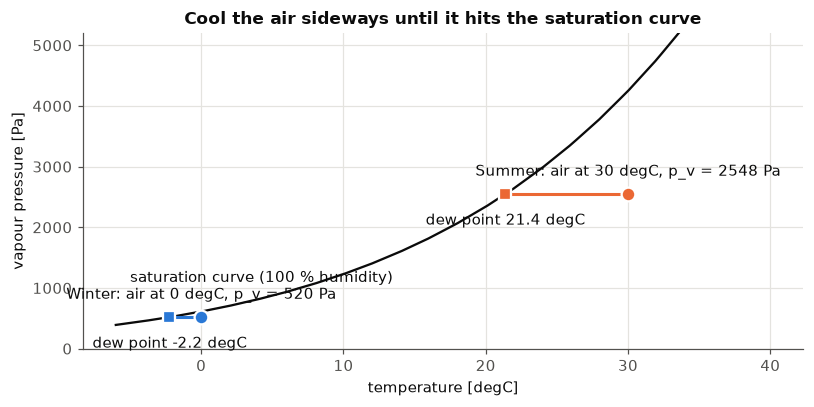

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(tt, p_sat(tt), color=INK, lw=1.5)
ax.text(-5, 1100, "saturation curve (100 % humidity)", color=INK)
for name, (t, phi), col in (("Summer", cases["Summer day"], SUMMER), ("Winter", cases["Winter day"], WINTER)):
    pv = phi * p_sat(t); tdp = t_sat(pv)
    ax.plot([tdp, t], [pv, pv], color=col, lw=2)                      # cooling at constant p_v
    ax.plot(t, pv, "o", color=col, ms=9, mec="white", mew=1.5)         # current state
    ax.plot(tdp, pv, "s", color=col, ms=8, mec="white", mew=1.5)       # dew point
    ax.annotate(f"{name}: air at {t} degC, p_v = {pv:.0f} Pa", (t, pv), xytext=(0, 12), textcoords="offset points", ha="center", color=INK)
    ax.annotate(f"dew point {tdp:.1f} degC", (tdp, pv), xytext=(0, -20), textcoords="offset points", ha="center", color=INK)
ax.set_xlabel("temperature [degC]"); ax.set_ylabel("vapour pressure [Pa]"); ax.set_ylim(0, 5200)
ax.set_title("Cool the air sideways until it hits the saturation curve")
plt.tight_layout(); plt.show()

**Reading it.** Circle = the air now. Square = its dew point. The horizontal line is the cooling path. Summer air only has to cool by about 8.6 °C before it fogs, winter air by about 2.2 °C.

## A5. Enthalpy: where is the energy hiding?

$h = \underbrace{t}_{\text{sensible}} + \underbrace{x(2500+1.84\,t)}_{\text{latent}}$

- **Sensible** heat is the warmth you can feel and measure with a thermometer.
- **Latent** heat is energy stored in the water vapour (what it took to evaporate it). You do not feel it directly, but an air conditioner must remove it to dry the air.

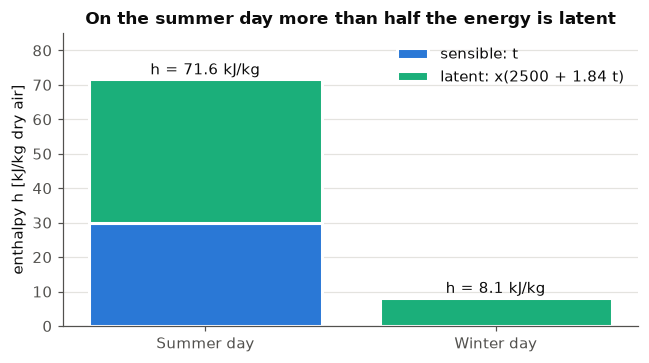

In [6]:
names = list(cases); sens, lat = [], []
for n in names:
    t, phi = cases[n]; x = humidity_ratio(phi * p_sat(t))
    sens.append(t); lat.append(x * (2500 + 1.84 * t))
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.bar(names, sens, color=BLUE, edgecolor="white", linewidth=2, label="sensible: t")
ax.bar(names, lat, bottom=sens, color=AQUA, edgecolor="white", linewidth=2, label="latent: x(2500 + 1.84 t)")
for i in range(2):
    ax.text(i, sens[i] + lat[i] + 1.5, f"h = {sens[i] + lat[i]:.1f} kJ/kg", ha="center")
ax.set_ylabel("enthalpy h [kJ/kg dry air]"); ax.set_ylim(0, 85); ax.legend(frameon=False, loc="upper right"); ax.grid(axis="x", visible=False)
ax.set_title("On the summer day more than half the energy is latent")
plt.tight_layout(); plt.show()

**Reading it.** In summer, about 42 of the 71.6 kJ/kg are latent, hidden in the humidity. Cooling this air to a comfortable temperature is only half the job: the air also has to be dried. In winter, the latent part (8.1) is the whole enthalpy, because 0 °C contributes no sensible energy.

## A6. Individual work: the whole day (Bucharest, Meteonorm data)

The sheet gives **24 hourly values** of $t$ and $\varphi$ for **August 8th** and **February 1st** (UTC hours; Romanian local time is UTC+3 in summer, UTC+2 in winter). We apply the same five steps to every hour.

In [7]:
hours = np.arange(1, 25)
t_s = np.array([22.5, 21.8, 21, 21, 20.7, 20.9, 22, 23.3, 24.4, 25.6, 26.3, 26.9, 27.3, 27.7, 27.9, 27.9, 27.3, 26.7, 25.9, 24.6, 23.3, 22, 20.6, 19.3])
f_s = np.array([83, 89, 90, 91, 89, 86, 80, 80, 62, 55, 54, 53, 48, 47, 46, 44, 56, 46, 49, 53, 53, 55, 59, 60])
t_w = np.array([3.5, 2.9, 2.2, 1.9, 1.6, 1.3, 1.1, 1.4, 3.3, 5.3, 6.7, 7.4, 7.9, 7.9, 7.7, 7, 5.8, 5.3, 4.8, 4.3, 3.8, 3.3, 2.8, 2.3])
f_w = np.array([79, 81, 84, 81, 83, 83, 85, 84, 77, 72, 73, 74, 69, 66, 67, 74, 78, 77, 77, 81, 82, 87, 86, 85])

def day_table(t, phi):
    pv = phi / 100 * p_sat(t); x = humidity_ratio(pv)
    return pd.DataFrame({"hour (UTC)": hours, "t": t, "phi": phi, "p_v [Pa]": pv.round(0), "x [g/kg]": (1000 * x).round(2),
                         "t_dp": t_sat(pv).round(1), "h [kJ/kg]": enthalpy(t, x).round(1)})
summer_day, winter_day = day_table(t_s, f_s), day_table(t_w, f_w)
print("SUMMER, 8 August");  display(summer_day.set_index("hour (UTC)").T.iloc[:, :12]); display(summer_day.set_index("hour (UTC)").T.iloc[:, 12:])
print("WINTER, 1 February"); display(winter_day.set_index("hour (UTC)").T.iloc[:, :12]); display(winter_day.set_index("hour (UTC)").T.iloc[:, 12:])

SUMMER, 8 August


hour (UTC),1,2,3,4,5,6,7,8,9,10,11,12
t,22.50,21.80,21.00,21.00,20.70,20.90,22.00,23.3,24.40,25.60,26.30,26.90
phi,83.00,89.00,90.00,91.00,89.00,86.00,80.00,80.0,62.00,55.00,54.00,53.00
p_v [Pa],2266.00,2327.00,2243.00,2268.00,2177.00,2130.00,2116.00,2293.0,1898.00,1809.00,1850.00,1883.00
x [g/kg],14.42,14.82,14.27,14.43,13.84,13.54,13.45,14.6,12.04,11.46,11.73,11.94
t_dp,19.50,19.90,19.30,19.50,18.80,18.50,18.40,19.7,16.60,15.90,16.30,16.50
h [kJ/kg],59.20,59.40,57.20,57.60,55.80,55.30,56.20,60.4,55.00,54.80,56.20,57.30


hour (UTC),13,14,15,16,17,18,19,20,21,22,23,24
t,27.30,27.70,27.90,27.90,27.30,26.70,25.90,24.60,23.3,22.00,20.60,19.30
phi,48.00,47.00,46.00,44.00,56.00,46.00,49.00,53.00,53.0,55.00,59.00,60.00
p_v [Pa],1745.00,1748.00,1731.00,1655.00,2036.00,1615.00,1639.00,1643.00,1519.0,1455.00,1434.00,1346.00
x [g/kg],11.05,11.07,10.95,10.47,12.93,10.21,10.37,10.39,9.6,9.18,9.05,8.49
t_dp,15.30,15.40,15.20,14.50,17.80,14.10,14.40,14.40,13.2,12.50,12.30,11.30
h [kJ/kg],55.50,55.90,55.80,54.60,60.30,52.70,52.30,51.00,47.7,45.30,43.60,40.80


WINTER, 1 February


hour (UTC),1,2,3,4,5,6,7,8,9,10,11,12
t,3.50,2.90,2.20,1.90,1.60,1.30,1.10,1.40,3.30,5.30,6.7,7.40
phi,79.00,81.00,84.00,81.00,83.00,83.00,85.00,84.00,77.00,72.00,73.0,74.00
p_v [Pa],621.00,611.00,602.00,568.00,570.00,558.00,564.00,569.00,597.00,643.00,718.0,763.00
x [g/kg],3.89,3.82,3.77,3.55,3.57,3.49,3.53,3.56,3.74,4.02,4.5,4.79
t_dp,0.20,-0.00,-0.20,-1.00,-1.00,-1.30,-1.10,-1.00,-0.30,0.70,2.2,3.10
h [kJ/kg],13.20,12.50,11.60,10.80,10.50,10.00,9.90,10.30,12.70,15.40,18.0,19.40


hour (UTC),13,14,15,16,17,18,19,20,21,22,23,24
t,7.90,7.90,7.70,7.00,5.80,5.3,4.80,4.30,3.80,3.30,2.80,2.30
phi,69.00,66.00,67.00,74.00,78.00,77.0,77.00,81.00,82.00,87.00,86.00,85.00
p_v [Pa],736.00,704.00,705.00,743.00,720.00,687.0,664.00,674.00,658.00,675.00,644.00,614.00
x [g/kg],4.61,4.41,4.42,4.66,4.51,4.3,4.16,4.22,4.12,4.23,4.03,3.84
t_dp,2.60,2.00,2.00,2.70,2.30,1.6,1.10,1.30,1.00,1.30,0.70,0.10
h [kJ/kg],19.50,19.00,18.80,18.70,17.10,16.1,15.20,14.90,14.10,13.90,12.90,11.90


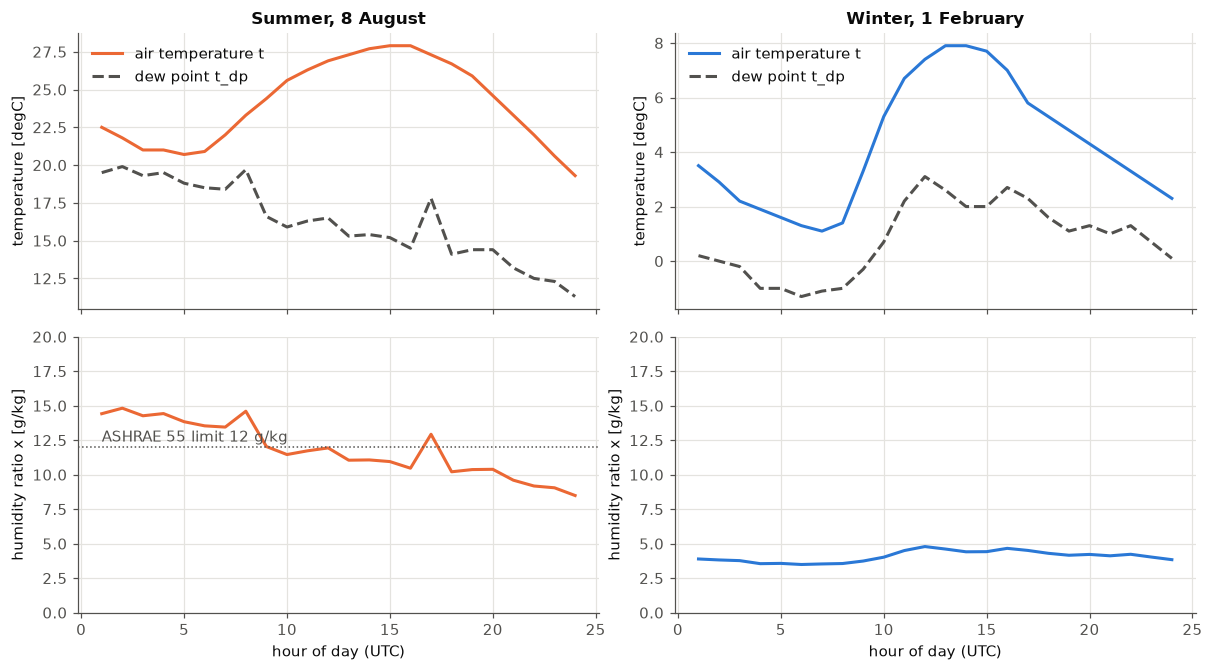

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.2), sharex=True)
for col, (name, df, colr) in enumerate((("Summer, 8 August", summer_day, SUMMER), ("Winter, 1 February", winter_day, WINTER))):
    ax = axes[0, col]
    ax.plot(df["hour (UTC)"], df["t"], color=colr, lw=2, label="air temperature t")
    ax.plot(df["hour (UTC)"], df["t_dp"], color=MUTED, lw=2, ls="--", label="dew point t_dp")
    ax.set_title(name); ax.set_ylabel("temperature [degC]"); ax.legend(frameon=False)
    ax = axes[1, col]
    ax.plot(df["hour (UTC)"], df["x [g/kg]"], color=colr, lw=2)
    ax.set_ylabel("humidity ratio x [g/kg]"); ax.set_xlabel("hour of day (UTC)")
axes[1, 0].set_ylim(0, 20); axes[1, 1].set_ylim(0, 20)
axes[1, 0].axhline(12, color=MUTED, lw=1, ls=":"); axes[1, 0].text(1, 12.4, "ASHRAE 55 limit 12 g/kg", color=MUTED)
plt.tight_layout(); plt.show()

**Reading it.**
- **Top row:** the gap between the solid line (air) and the dashed line (dew point) is how far the air is from fog. At night and early morning in summer the gap is only about 1.5 to 3.6 °C (RH 80 to 91 %); in the afternoon it is about 10 to 13 °C.
- **Bottom row:** summer humidity ratio is above the 12 g/kg line from 01:00 to 08:00 UTC (13.4 to 14.8 g/kg) and again at 17:00, and drops to 10 to 12 g/kg in the afternoon. So even though the *relative* humidity is lowest in the afternoon, the air is still very moist in absolute terms. Winter air is always dry in absolute terms (3.5 to 4.8 g/kg), which is why heated winter rooms often feel too dry.

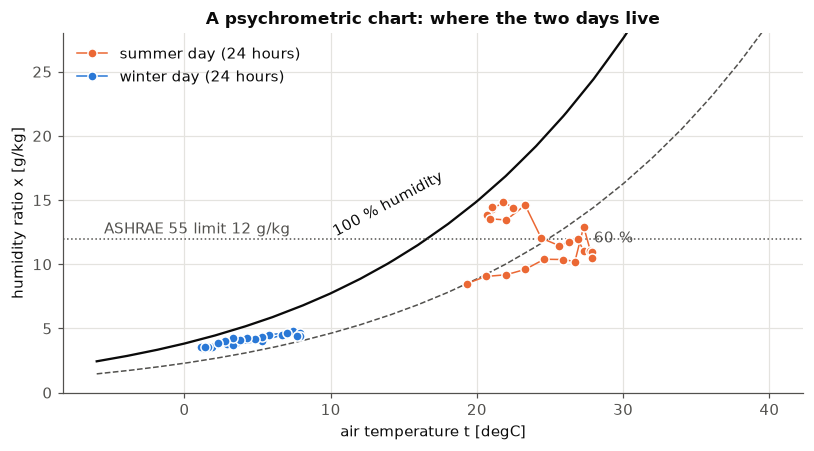

In [9]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
tg = np.linspace(-6, 40, 200)
xsat = 1000 * humidity_ratio(p_sat(tg)); x60 = 1000 * humidity_ratio(0.6 * p_sat(tg))
ax.plot(tg, xsat, color=INK, lw=1.5); ax.text(10, 12.2, "100 % humidity", color=INK, rotation=28)
ax.plot(tg, x60, color=MUTED, lw=1, ls="--"); ax.text(28, 11.7, "60 %", color=MUTED)
ax.axhline(12, color=MUTED, lw=1, ls=":"); ax.text(-5.5, 12.4, "ASHRAE 55 limit 12 g/kg", color=MUTED)
ax.plot(summer_day["t"], summer_day["x [g/kg]"], "o-", color=SUMMER, ms=6, lw=1, mec="white", mew=1, label="summer day (24 hours)")
ax.plot(winter_day["t"], winter_day["x [g/kg]"], "o-", color=WINTER, ms=6, lw=1, mec="white", mew=1, label="winter day (24 hours)")
ax.set_xlabel("air temperature t [degC]"); ax.set_ylabel("humidity ratio x [g/kg]"); ax.set_ylim(0, 28); ax.legend(frameon=False, loc="upper left")
ax.set_title("A psychrometric chart: where the two days live")
plt.tight_layout(); plt.show()

**Reading it.** This is the classic *psychrometric chart*: temperature across, water content up. Each dot is one hour. The winter cloud sits low-left (cold, dry), the summer cloud high-right (warm, humid). The black curve is the ceiling: no dot can be above it. Air conditioning moves summer dots **down** (drying) and **left** (cooling) toward the comfort zone.

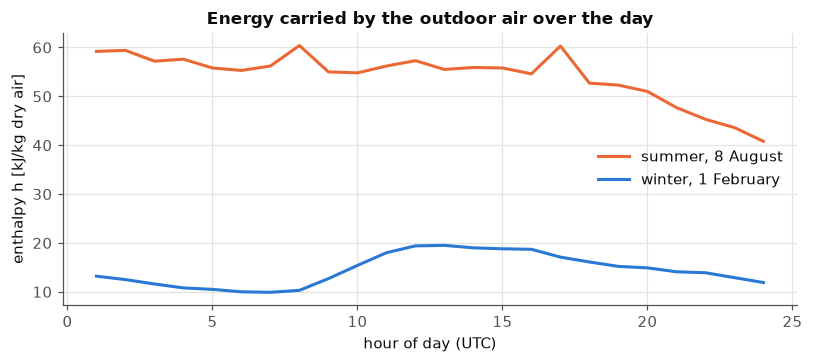

Summer: h from 40.8 to 60.4 kJ/kg;  winter: 9.9 to 19.5 kJ/kg


In [10]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.plot(hours, summer_day["h [kJ/kg]"], color=SUMMER, lw=2, label="summer, 8 August")
ax.plot(hours, winter_day["h [kJ/kg]"], color=WINTER, lw=2, label="winter, 1 February")
ax.set_xlabel("hour of day (UTC)"); ax.set_ylabel("enthalpy h [kJ/kg dry air]"); ax.legend(frameon=False)
ax.set_title("Energy carried by the outdoor air over the day")
plt.tight_layout(); plt.show()
print(f"Summer: h from {summer_day['h [kJ/kg]'].min()} to {summer_day['h [kJ/kg]'].max()} kJ/kg;  winter: {winter_day['h [kJ/kg]'].min()} to {winter_day['h [kJ/kg]'].max()} kJ/kg")

**Reading it.** The summer air carries 41 to 60 kJ/kg and the winter air only 10 to 20 kJ/kg, roughly three times as much. An air-handling unit's workload follows these curves: the higher $h$, the more energy needed to bring the air to indoor conditions. That is the link to *energy management*, the course topic.

# Part B: Sheet 2, the comfort challenge (PMV, PPD, $t_o$)

Sheet 1 described the air. Now we look at the **person in the air**.

## B0. The big picture: six factors, six drains

The lecture says thermal comfort is a **heat balance** between body and environment, controlled by **four environmental** and **two personal** factors:

| Environmental | Personal |
|---|---|
| air temperature $t_a$, mean radiant temperature $t_{mr}$, air speed $v$, humidity RH | metabolic rate $M_{met}$, clothing $I_{clo}$ |

The body makes heat $M$. Six paths remove it ($RL_1$ to $RL_6$). What remains is the load $L$, and $PMV = TS\cdot L$.

Which factor drives which drain? The table below changes each factor by one typical step and shows how many W/m² each drain moves by (orange = drain grows, blue = shrinks). The hot summer day is the base case.

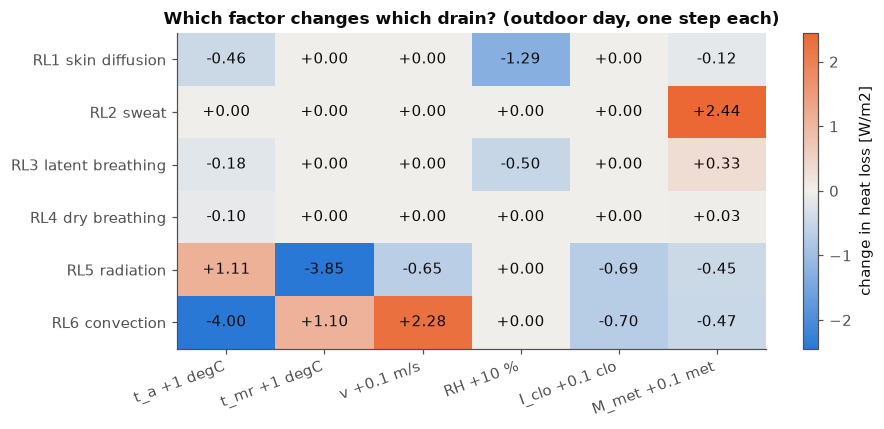

In [11]:
BASE = dict(t_a=30, t_mr=30.5, v=0.15, rh=60, i_clo=0.5, m_met=1.2)
STEP = {"t_a +1 degC": ("t_a", 1), "t_mr +1 degC": ("t_mr", 1), "v +0.1 m/s": ("v", 0.1),
        "RH +10 %": ("rh", 10), "I_clo +0.1 clo": ("i_clo", 0.1), "M_met +0.1 met": ("m_met", 0.1)}
keys = ["RL1", "RL2", "RL3", "RL4", "RL5", "RL6"]
*_, d0 = calculate_pmv_ppd(**BASE, details=True)
grid = np.array([[calculate_pmv_ppd(**{**BASE, p: BASE[p] + s}, details=True)[-1][k] - d0[k] for p, s in STEP.values()] for k in keys])
labels = ["RL1 skin diffusion", "RL2 sweat", "RL3 latent breathing", "RL4 dry breathing", "RL5 radiation", "RL6 convection"]
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
cmap = LinearSegmentedColormap.from_list("div", [BLUE, "#f0efec", ORANGE])
fig, ax = plt.subplots(figsize=(8.5, 4))
im = ax.imshow(grid, cmap=cmap, norm=TwoSlopeNorm(0, vmin=-grid.max(), vmax=grid.max()), aspect="auto")
ax.set_xticks(range(6)); ax.set_xticklabels(list(STEP), rotation=20, ha="right"); ax.set_yticks(range(6)); ax.set_yticklabels(labels); ax.grid(False)
for i in range(6):
    for j in range(6):
        ax.text(j, i, f"{grid[i, j]:+.2f}", ha="center", va="center", color=INK)
fig.colorbar(im, label="change in heat loss [W/m2]"); ax.set_title("Which factor changes which drain? (outdoor day, one step each)")
plt.tight_layout(); plt.show()

**Reading it.** Each column is a factor, each row a drain.
- **Humidity** acts only on the two vapour drains ($RL_1$, $RL_3$): it is the $p_v$ of sheet 1. More humid air means *less* vapour loss (blue).
- **Metabolic rate** mostly adds **sweat** ($RL_2$, +2.4 W/m² per 0.1 met). The other drains change slightly, because a busier body has a cooler skin and clothing.
- **Air speed** acts on convection ($RL_6$, +2.3 W/m² per 0.1 m/s). Radiation drops a little because the clothes get cooler.
- **$t_a$ and $t_{mr}$ push in opposite directions on the two big drains:** warmer air shrinks convection loss (−4.0), warmer walls shrink radiation loss (−3.9), while the other drain rises slightly. In both cases total heat loss falls and PMV rises.
- **Clothing** reduces both radiation and convection (about −0.7 each per 0.1 clo): it is the insulation.

## B1. Metabolic rate in depth (lecture slides 16 to 20)

A resting adult produces about **100 W** of heat. Per square metre of skin (about 1.7 m² on average; 1.8 m² for a European man, 1.6 m² for a woman):

$$\frac{100\ \mathrm{W}}{1.7\ \mathrm{m^2}} \approx 58\ \mathrm{W/m^2} = 1\ \mathrm{met}$$

The lab uses the exact value 58.15 W/m². The lecture also gives two helpful formulas.

**Skin temperature** falls as activity rises (more sweat cools the skin): $t_{sk} = 35.7 - 0.0275\,(M - W)$, with $W$ the mechanical work done (zero for desk work). The lab's clothing-balance equation uses $35.7 - 0.028\,M$, the same idea rounded.

**Measuring M from breathing** (Nishi 1981): $M = 21\,(0.23\,RQ+0.77)\,\dfrac{\dot V_{O_2}}{A_D}$, where $RQ$ is the *respiratory quotient* (CO₂ out / O₂ in; it tells which fuel the body burns: about 0.7 for fats, 1.0 for carbohydrates, about 0.83 for a mixed diet), $\dot V_{O_2}$ is oxygen consumption (mL/s) and $A_D$ is skin area (m²).

,RQ,O2 use [mL/s],M [W/m2],M [met] = M / 58
Light work,0.83,7,78.47,1.35
Heavy work,0.90,20,227.97,3.93


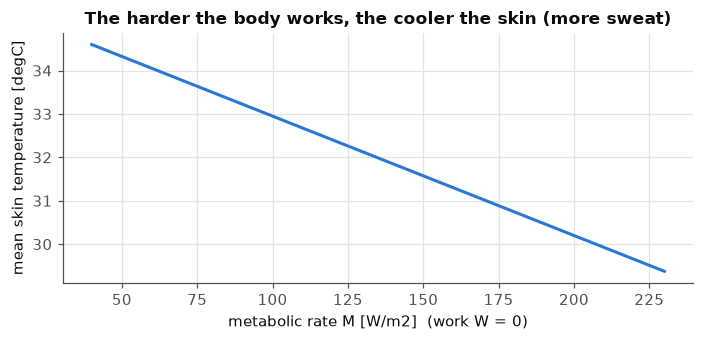

In [12]:
def metabolic_rate_nishi(rq, vo2_ml_s, area=1.8):          # M [W/m2] from breathing
    return 21 * (0.23 * rq + 0.77) * vo2_ml_s / area

ex = pd.DataFrame({"RQ": [0.83, 0.90], "O2 use [mL/s]": [7, 20]}, index=["Light work", "Heavy work"])
ex["M [W/m2]"] = [round(metabolic_rate_nishi(r, v), 2) for r, v in zip(ex["RQ"], ex["O2 use [mL/s]"])]
ex["M [met] = M / 58"] = (ex["M [W/m2]"] / 58).round(2)
display(ex)                                                   # lecture: 78.47 W/m2, 1.35 met and 227.96 W/m2, 3.93 met

M = np.linspace(40, 230, 100)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(M, 35.7 - 0.0275 * M, color=BLUE, lw=2)
ax.set_xlabel("metabolic rate M [W/m2]  (work W = 0)"); ax.set_ylabel("mean skin temperature [degC]")
ax.set_title("The harder the body works, the cooler the skin (more sweat)")
plt.tight_layout(); plt.show()

**Reading it.** Light work gives 1.35 met, heavy work 3.93 met, matching the lecture. The skin temperature drops about 1 °C between resting and 1.5 met, which is why $t_{cl}$ depends on $M$ in the iteration. Above about 3 met the activity is poorly defined and the values can be off by ±50 %, so PMV is a less reliable number there.

## B2. Clothing in depth

- **clo** is the unit of clothing insulation. **1 clo = 0.155 m²·K/W**: the thermal resistance of a typical winter business suit. 0.5 clo is light summer clothing.
- Clothes also **enlarge the surface** that exchanges heat. The *clothing area factor* $f_{cl}$ = clothed surface / nude surface:

$$f_{cl}=\begin{cases}1+1.29\,I_{cl} & I_{cl}<0.078\\[2pt] 1.05+0.645\,I_{cl} & I_{cl}\ge0.078\end{cases}$$

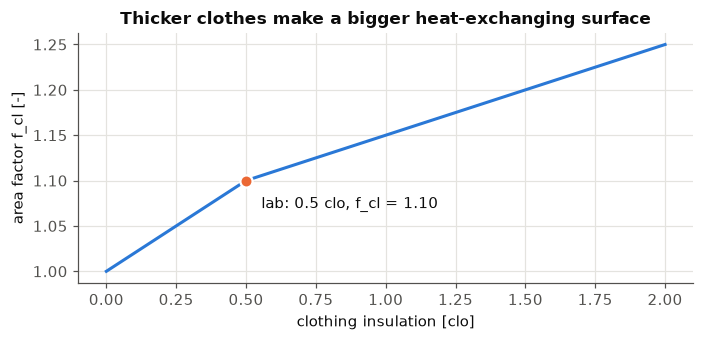

0.5 clo = 0.0775 m2K/W (< 0.078 uses the first branch)


In [13]:
clo = np.linspace(0, 2, 200); icl = 0.155 * clo
fcl = np.where(icl < 0.078, 1 + 1.29 * icl, 1.05 + 0.645 * icl)
fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(clo, fcl, color=BLUE, lw=2)
ax.plot(0.5, 1 + 1.29 * 0.155 * 0.5, "o", color=ORANGE, ms=8, mec="white", mew=1.5); ax.annotate("lab: 0.5 clo, f_cl = 1.10", (0.5, 1.1), xytext=(10, -18), textcoords="offset points")
ax.set_xlabel("clothing insulation [clo]"); ax.set_ylabel("area factor f_cl [-]"); ax.set_title("Thicker clothes make a bigger heat-exchanging surface")
plt.tight_layout(); plt.show()
print("0.5 clo =", 0.5 * 0.155, "m2K/W (< 0.078 uses the first branch)")

**Reading it.** At 0.5 clo, $I_{cl} = 0.0775 < 0.078$, so the **first** branch is used (a tiny difference from the second one). $f_{cl}=1.10$: a lightly dressed body exchanges heat over a surface 10 % larger than bare skin.

## B3. Mean radiant temperature and operative temperature, properly

**Mean radiant temperature** $t_{mr}$ is the average temperature of everything the body "sees", weighted by how much of the body faces each surface. The lecture gives weights for a **seated** person (up/down, right/left, front/back):

$$t_{mr}=\frac{0.18(t_{up}+t_{down})+0.22(t_{right}+t_{left})+0.30(t_{front}+t_{back})}{2(0.18+0.22+0.30)}$$

(standing: 0.08, 0.23, 0.35). In the lab we are simply **given** $t_{mr}$ = 30.5 °C. Here is how it would come from real surfaces.

In [14]:
def t_mr_seated(up, down, right, left, front, back):
    return (0.18 * (up + down) + 0.22 * (right + left) + 0.30 * (front + back)) / (2 * (0.18 + 0.22 + 0.30))
def t_mr_standing(up, down, right, left, front, back):
    return (0.08 * (up + down) + 0.23 * (right + left) + 0.35 * (front + back)) / (2 * (0.08 + 0.23 + 0.35))

# example (made up): sunny summer office. Ceiling 28, floor 26, side walls 27, window in front 34, wall behind 27
surf = dict(up=28, down=26, right=27, left=27, front=34, back=27)
print(f"seated: {t_mr_seated(**surf):.2f} degC    standing: {t_mr_standing(**surf):.2f} degC   (plain average of the six: {np.mean(list(surf.values())):.2f})")

seated: 28.50 degC    standing: 28.86 degC   (plain average of the six: 28.17)


**Operative temperature.** The lecture's physical definition is a weighted average with the two heat-transfer coefficients as weights:

$$t_o=\frac{h_c\,t_a+h_r\,t_{mr}}{h_c+h_r},\qquad h_r = 4\,\varepsilon\,\sigma\,\frac{A_r}{A_D}\Big(273.2+\frac{t_{cl}+t_{mr}}{2}\Big)^3$$

with $h_c$ convective and $h_r$ radiative coefficient [W/(m²·K)], $\varepsilon$ emissivity (assumed 0.95 here), $\sigma = 5.67\cdot10^{-8}$ W/(m²K⁴), $A_r/A_D$ = 0.70 sitting or 0.73 standing.

The **sheet simplifies this to fixed weights** (0.5/0.5, 0.6/0.4, 0.7/0.3 depending on air speed). Let us check that the simplification is reasonable.

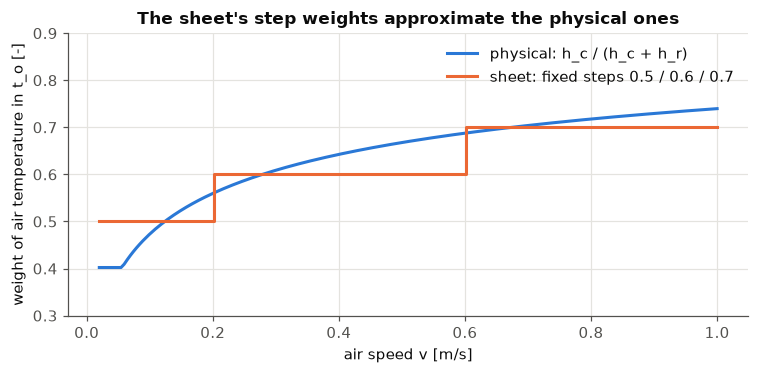

h_r = 4.26 W/m2K, h_c(0.15 m/s) = 4.66 W/m2K -> physical weight 0.52 vs sheet 0.50
t_o physical: 30.24  t_o sheet: 30.25


In [15]:
eps, sigma, ar_ad = 0.95, 5.67e-8, 0.70                         # emissivity assumed; sitting person
t_a_, t_mr_, t_cl_ = 30, 30.5, 32.1                               # lab day; t_cl from the iteration
h_r = 4 * eps * sigma * ar_ad * (273.2 + (t_cl_ + t_mr_) / 2) ** 3
v_axis = np.linspace(0.02, 1.0, 200)
h_c = np.maximum(12.1 * np.sqrt(v_axis), 2.38 * abs(t_cl_ - t_a_) ** 0.25)
w_air = h_c / (h_c + h_r)                                         # weight of air temperature in t_o
w_sheet = np.where(v_axis < 0.2, 0.5, np.where(v_axis < 0.6, 0.6, 0.7))
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(v_axis, w_air, color=BLUE, lw=2, label="physical: h_c / (h_c + h_r)")
ax.step(v_axis, w_sheet, color=ORANGE, lw=2, where="post", label="sheet: fixed steps 0.5 / 0.6 / 0.7")
ax.set_xlabel("air speed v [m/s]"); ax.set_ylabel("weight of air temperature in t_o [-]"); ax.set_ylim(0.3, 0.9); ax.legend(frameon=False)
ax.set_title("The sheet's step weights approximate the physical ones")
plt.tight_layout(); plt.show()
i = np.argmin(abs(v_axis - 0.15)); print(f"h_r = {h_r:.2f} W/m2K, h_c(0.15 m/s) = {h_c[i]:.2f} W/m2K -> physical weight {w_air[i]:.2f} vs sheet 0.50")
print("t_o physical:", round(w_air[i] * 30 + (1 - w_air[i]) * 30.5, 2), " t_o sheet: 30.25")

**Reading it.** The physical curve rises with air speed (more convection, so air counts more), just like the sheet's steps. At the lab's 0.15 m/s the physical weight is about 0.52 against the sheet's 0.50, so $t_o$ is 30.24 or 30.25 °C: practically identical. The sheet's version needs no iteration and no emissivity, which makes it easy to code and good enough for control.

## B4. The heart of the code: the $t_{cl}$ iteration (what the sheet calls Step 3)

Why iterate? $t_{cl}$ sets how much heat leaves by radiation ($\propto T_{cl}^4$) and convection ($h_c$ depends on $t_{cl}-t_a$), and those losses in turn set $t_{cl}$. The sheet's recipe is *guess, recompute, repeat until the change is below $\epsilon=0.0015$*.

**Why our numbers match the sheet exactly.** The reference result (PMV 1.767, 8 iterations) only appears with this ISO 7730 form: kelvin = °C + 273.15, the balance constant 308.7 (=35.7 + 273), unknown $x=T_{cl}/100$, old/new values averaged each round, and the stopping test applied to $x$ (so 0.0015 means 0.15 K). A looser or different choice gives PMV 1.71 to 1.76, which is close but does not match the sheet.

In [16]:
pmv, ppd, t_o, n, d = calculate_pmv_ppd(**BASE, details=True)
hist = pd.DataFrame({"iteration": range(len(d["history"])), "t_cl guess [degC]": np.round(d["history"], 4)})
hist["change vs previous"] = hist["t_cl guess [degC]"].diff().round(4)
display(hist.set_index("iteration").T)
print(f"-> t_cl = {d['t_cl']:.2f} degC after {n} iterations;  h_c = {d['h_c']:.2f} W/m2K;  f_cl = {d['f_cl']:.2f}")

iteration,0,1,2,3,4,5,6,7,8
t_cl guess [degC],32.6196,-38.2183,19.1346,27.9415,30.7089,31.6252,31.9464,32.0615,32.1030
change vs previous,NaN,-70.8379,57.3529,8.8069,2.7674,0.9163,0.3212,0.1151,0.0415


-> t_cl = 32.10 degC after 8 iterations;  h_c = 4.69 W/m2K;  f_cl = 1.10


## B5. Reading PMV and PPD like a standard (lecture slides 28 to 30)

- **PMV scale:** +3 hot, +2 warm, +1 slightly warm, 0 neutral, −1 slightly cool, −2 cool, −3 cold.
- **Even at PMV = 0, at least 5 % of people are dissatisfied.**
- **Validity:** the model assumes sweating is small, so PMV is only applicable for $-2 < PMV < +2$. It is **not applicable for hot environments**.
- **Romanian regulation (I5)** sorts rooms into four categories:

| Category | Who it suits | PPD | PMV range |
|---|---|---|---|
| **I** high | children, elderly, sick | < 6 % | −0.2 … 0.2 |
| **II** medium | normal for new / renovated buildings | < 10 % | −0.5 … 0.5 |
| **III** moderate | existing buildings | < 15 % | −0.7 … 0.7 |
| **IV** low | short periods only | > 15 % | beyond ±0.7 |

The lab's target, −0.5 < PMV < 0.5, is category **II**.

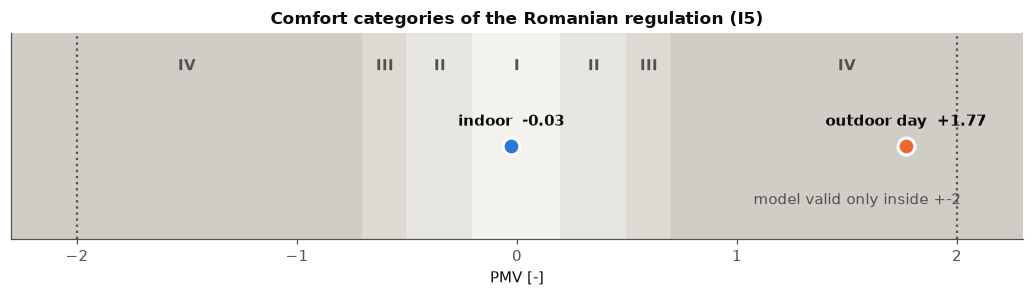

In [17]:
pm_out = calculate_pmv_ppd(**BASE)[0]
pm_in = calculate_pmv_ppd(t_a=24.5, t_mr=25, v=0.15, rh=60, i_clo=0.5, m_met=1.2)[0]
fig, ax = plt.subplots(figsize=(9.5, 2.8))
cats = [("IV", -2.3, -0.7, "#cfcdc6"), ("III", -0.7, -0.5, "#dcdad3"), ("II", -0.5, -0.2, "#e8e6e0"), ("I", -0.2, 0.2, "#f3f2ee"),
        ("II", 0.2, 0.5, "#e8e6e0"), ("III", 0.5, 0.7, "#dcdad3"), ("IV", 0.7, 2.3, "#cfcdc6")]
for name, lo, hi, colr in cats:
    ax.axvspan(lo, hi, color=colr, zorder=0); ax.text((lo + hi) / 2, 0.82, name, ha="center", fontweight="bold", color=MUTED)
ax.axvline(-2, color=MUTED, ls=":"); ax.axvline(2, color=MUTED, ls=":"); ax.text(2.02, 0.15, "model valid only inside +-2", color=MUTED, ha="right", va="bottom")
for xv, lab, colr in ((pm_in, "indoor", BLUE), (pm_out, "outdoor day", ORANGE)):
    ax.plot(xv, 0.45, "o", color=colr, ms=11, mec="white", mew=2); ax.text(xv, 0.55, f"{lab}  {xv:+.2f}", ha="center", fontweight="bold")
ax.set_xlim(-2.3, 2.3); ax.set_ylim(0, 1); ax.set_yticks([]); ax.grid(False); ax.set_xlabel("PMV [-]")
ax.set_title("Comfort categories of the Romanian regulation (I5)")
plt.tight_layout(); plt.show()

**Reading it.** Our indoor room (PMV −0.03) sits in the centre, **category I**, the strictest one (|PMV| < 0.2, PPD 5.0 % < 6 %). The outdoor day (+1.77) is in category IV, and its value is just inside the ±2 validity limit, so the number can be trusted but is close to the edge.

## B6. Applying the comfort model to the whole summer day

The challenge refers to *"the considered day in the previous simulation"*. Here we run the hourly summer data of sheet 1 through the comfort program, assuming (as the sheet does for its single case) $t_{mr}=t_a+0.5$ °C, $v=0.15$ m/s, 0.5 clo, 1.2 met. **This is an extension, not something the sheet asks for**: it shows how the outdoor air would feel to a person dressed for summer.

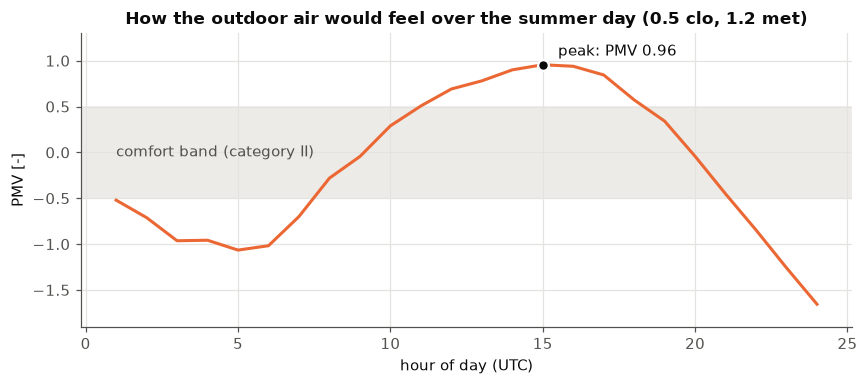

PMV from -1.66 (hour 24) to 0.96 (hour 15)


In [18]:
pmv_day = np.array([calculate_pmv_ppd(t, t + 0.5, rh=f)[0] for t, f in zip(t_s, f_s)])
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.axhspan(-0.5, 0.5, color=BAND, zorder=0); ax.text(1, 0.0, "comfort band (category II)", color=MUTED, va="center")
ax.plot(hours, pmv_day, color=SUMMER, lw=2)
ax.plot(15, pmv_day[14], "o", color=INK, ms=7, mec="white", mew=1.5)
ax.annotate(f"peak: PMV {pmv_day[14]:.2f}", (15, pmv_day[14]), xytext=(10, 6), textcoords="offset points", ha="left")
ax.set_ylim(-1.9, 1.3)
ax.set_xlabel("hour of day (UTC)"); ax.set_ylabel("PMV [-]"); ax.set_title("How the outdoor air would feel over the summer day (0.5 clo, 1.2 met)")
plt.tight_layout(); plt.show()
print(f"PMV from {pmv_day.min():.2f} (hour {hours[pmv_day.argmin()]}) to {pmv_day.max():.2f} (hour {hours[pmv_day.argmax()]})")

**Reading it.** The air is **cool** at night and in the early morning (PMV down to −1.66 at the last hour, 19.3 °C), comfortable around 08:00 to 11:00 and again 18:00 to 21:00 UTC, and **warm** from noon to evening (peak +0.96 at 15:00 UTC, 27.9 °C and 46 %). The sheet's example state (30 °C, 60 %) is hotter and more humid than any hour of this particular day, which is why its PMV (+1.77) is higher than this day's peak.

## B7. Finding the indoor conditions (the second half of the challenge)

The sheet fixes RH, $v$, clothing and activity, and lets us change $t_a$, $t_{mr}$ (and RH). **Summer rule: $t_{mr}=t_a+0.5$.** We search for the $t_a$ range where $-0.5<PMV<0.5$, and compare with the ASHRAE 55 operative-temperature ranges from the lecture: **23 to 26 °C in summer (0.5 clo), 20 to 24 °C in winter (1.0 clo)**.

Summer clothes (0.5 clo, 1.2 met): -0.5 < PMV < 0.5 for t_a from 23.01 to 26.14 degC  (t_o 23.26 to 26.39)
Winter clothes (1.0 clo, 1.2 met): -0.5 < PMV < 0.5 for t_a from 19.16 to 23.51 degC  (t_o 19.41 to 23.76)


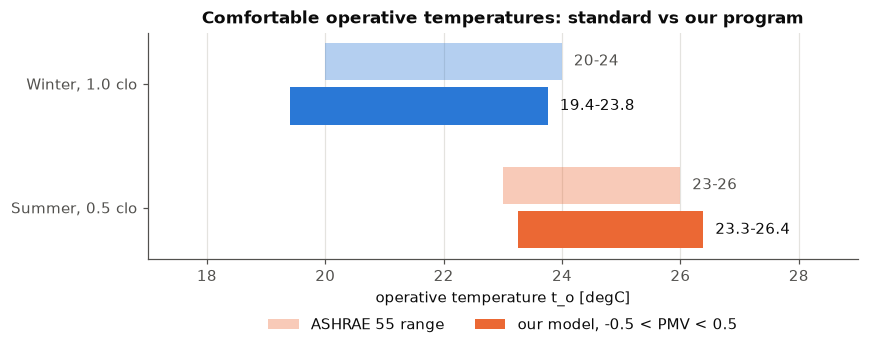

In [19]:
f = lambda ta, **kw: calculate_pmv_ppd(ta, ta + 0.5, **kw)[0]
lo_s, hi_s = brentq(lambda t: f(t) + 0.5, 15, 30), brentq(lambda t: f(t) - 0.5, 15, 30)
print(f"Summer clothes (0.5 clo, 1.2 met): -0.5 < PMV < 0.5 for t_a from {lo_s:.2f} to {hi_s:.2f} degC  (t_o {lo_s + 0.25:.2f} to {hi_s + 0.25:.2f})")
lo_w, hi_w = brentq(lambda t: f(t, i_clo=1.0) + 0.5, 10, 30), brentq(lambda t: f(t, i_clo=1.0) - 0.5, 10, 30)
print(f"Winter clothes (1.0 clo, 1.2 met): -0.5 < PMV < 0.5 for t_a from {lo_w:.2f} to {hi_w:.2f} degC  (t_o {lo_w + 0.25:.2f} to {hi_w + 0.25:.2f})")

fig, ax = plt.subplots(figsize=(8, 3.4))
for y, (name, lo, hi, a, b, colr) in enumerate((("Summer, 0.5 clo", lo_s + .25, hi_s + .25, 23, 26, SUMMER), ("Winter, 1.0 clo", lo_w + .25, hi_w + .25, 20, 24, WINTER))):
    ax.barh(y + 0.18, b - a, left=a, height=0.3, color=colr, alpha=0.35, label="ASHRAE 55 range" if y == 0 else None)
    ax.barh(y - 0.18, hi - lo, left=lo, height=0.3, color=colr, label="our model, -0.5 < PMV < 0.5" if y == 0 else None)
    ax.text(b + 0.2, y + 0.18, f"{a}-{b}", va="center", color=MUTED); ax.text(hi + 0.2, y - 0.18, f"{lo:.1f}-{hi:.1f}", va="center")
ax.set_yticks([0, 1]); ax.set_yticklabels(["Summer, 0.5 clo", "Winter, 1.0 clo"]); ax.set_xlim(17, 29); ax.grid(axis="y", visible=False)
ax.set_xlabel("operative temperature t_o [degC]"); ax.set_title("Comfortable operative temperatures: standard vs our program")
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
plt.tight_layout(); plt.show()

**Reading it.** Light bars = the ASHRAE 55 ranges from the lecture. Solid bars = what our PMV program says (PMV between ±0.5). They overlap well, which is a good sign the code is right: the program reproduces the standard's comfort zone. Winter people wear twice the clothing, so the comfortable air temperature is lower.

## B8. Why the comfortable temperature depends on activity

Lecture slide 24: for activity above 70 W/m² the comfortable operative temperature **drops**, because the body makes more heat. Our program shows the same effect (summer clothes, $t_{mr}=t_a+0.5$):

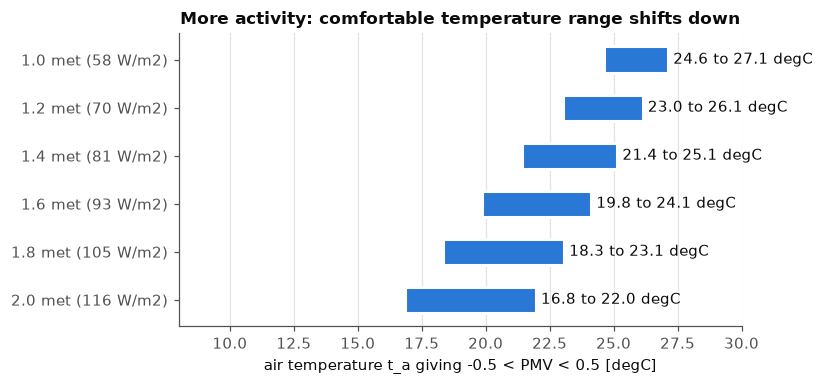

In [20]:
mets = [1.0, 1.2, 1.4, 1.6, 1.8, 2.0]
rng = [(brentq(lambda t: f(t, m_met=m) + 0.5, 5, 30), brentq(lambda t: f(t, m_met=m) - 0.5, 5, 30)) for m in mets]
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for i, (m, (a, b)) in enumerate(zip(mets, rng)):
    ax.barh(i, b - a, left=a, height=0.55, color=BLUE, edgecolor="white", linewidth=2)
    ax.text(b + 0.2, i, f"{a:.1f} to {b:.1f} degC", va="center")
ax.set_yticks(range(len(mets))); ax.set_yticklabels([f"{m} met ({m * 58.15:.0f} W/m2)" for m in mets]); ax.invert_yaxis()
ax.set_xlim(8, 30); ax.grid(axis="y", visible=False); ax.set_xlabel("air temperature t_a giving -0.5 < PMV < 0.5 [degC]")
ax.set_title("More activity: comfortable temperature range shifts down")
plt.tight_layout(); plt.show()

**Reading it.** Every extra 0.2 met lowers the comfortable air temperature by about 1.3 °C (the range is 24.6 to 27.1 °C at 1.0 met and 16.8 to 22.0 °C at 2.0 met). So a room that is perfect for a seated student feels hot to someone doing a lab practical on their feet. This is exactly the information a smart controller needs from occupancy data (chapter 4 of the course).

## B9. Summary: what to hand in and how the pieces fit

| Question | Sheet | Answer |
|---|---|---|
| Mass / density of air in 6×4×3 m room at 25 °C | 1 | 84.14 kg, 1.17 kg/m³ (slide: 1.16) |
| Summer 30 °C, 60 %: $p_{sat}$, $p_v$, $x$, $t_{dp}$, $h$ | 1 | 4247 Pa, 2548 Pa, 16.26 g/kg, 21.4 °C, 71.6 kJ/kg |
| Winter 0 °C, 85 %: same | 1 | 611.2 Pa, 519.5 Pa, 3.25 g/kg, −2.2 °C, 8.1 kJ/kg |
| Outdoor comfort (30 / 30.5 °C, 60 %) | 2 | PMV 1.767, PPD 65.3 %, $t_o$ 30.25 °C, 8 iterations |
| Indoor comfort (24.5 / 25 °C, 60 %) | 2 | PMV −0.027, PPD 5.0 %, $t_o$ 24.75 °C, 8 iterations (category I) |

In [21]:
print(sheet1.T.to_string()); print()
for name, cs in (("Outdoor", BASE), ("Indoor", dict(t_a=24.5, t_mr=25, v=0.15, rh=60, i_clo=0.5, m_met=1.2))):
    pmv, ppd, t_o, n = calculate_pmv_ppd(**cs)
    print(f"{name}:  PMV= {pmv:.3f}   PPD= {ppd:.1f} %   t_o= {t_o:.2f} degC   n iterations= {n}")

            t [degC]  phi [%]  p_sat(t) [Pa]  p_v = phi*p_sat [Pa]  x [g/kg]  t_dp [degC]  h [kJ/kg]
Summer day      30.0     60.0         4247.0                2548.2     16.26        21.37      71.56
Winter day       0.0     85.0          611.2                 519.5      3.25        -2.23       8.12

Outdoor:  PMV= 1.767   PPD= 65.3 %   t_o= 30.25 degC   n iterations= 8
Indoor:  PMV= -0.027   PPD= 5.0 %   t_o= 24.75 degC   n iterations= 8
